# 9. Todos los modelos originales de la revisión frente al modelo base

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** El objetivo del entregable es usar modelos **que no se habían aplicado** a la clasificación del estrato
con datos catastrales (la revisión bibliográfica, capítulo 1) y comprobar si alguno **supera al modelo base**. El
capítulo 8 respondió para el modelo principal, el XGBoost geográfico. ¿Qué pasa con **los demás candidatos** de la
revisión?

**Respuesta corta.** Sin información del entorno (ronda 1), ningún candidato superaba al modelo base en el test. Con
la vecindad física y todos los datos, **tres modelos originales lo superan con significancia estadística**: el
XGBoost geográfico, el **Rotation Forest** y el **stacking** (30 bloques espaciales, Wilcoxon con Holm, p < 0.01,
efecto mediano a grande). El Rotation Forest es además el único cuyo intervalo de test frente al base excluye el 0
(+0.099 de F1, IC 95 % [+0.024, +0.170]). Pero **ninguno supera significativamente a los modelos convencionales que
reciben la misma información**: la mejora la explica sobre todo la vecindad física.
```

Este capítulo se agregó a la versión 3 el 19 de octubre de 2026. Los cálculos se hicieron con el código del
Entregable 3 (carpeta `mejoras/` de su repositorio), con **el mismo protocolo del capítulo 8**: todas las viviendas,
los mismos 5 pliegues kNNDM de zonas nuevas y el mismo test. Los resultados están copiados en `datos/revision_v3/`.

## 9.1 Los nueve candidatos de la revisión y cuáles se probaron

La Tabla III de la revisión reúne nueve modelos con evidencia de reducir el error frente a los clasificadores
convencionales y que **nunca se habían aplicado** al estrato con datos catastrales (el capítulo 1 lista los cinco de
mayor prioridad). Todos son, en ese sentido, **modelos originales para esta aplicación**.

| # | Candidato (Tabla III) | Qué propone | ¿Se probó? | Dónde |
|---|---|---|---|---|
| 1 | **XGBoost geográfico** (Grekousis, 2025) | XGBoost global más XGBoost locales con pesos espaciales | **Sí: modelo principal**, adaptado a clasificación | caps. 4, 6, 8 y sección 9.3 |
| 2 | GWO-XGBoost | XGBoost con hiperparámetros optimizados por el algoritmo del lobo gris | Como idea: es un optimizador, no un modelo; el Entregable 3 comparó cuatro optimizadores y empatan | Entregable 3, cap. 3 |
| 3 | Bagged TAO Trees | Ensamble de árboles oblicuos optimizados | No: no tiene una implementación abierta confiable en Python | — |
| 4 | **RF + SVM en dos etapas** | Random Forest elige las variables y una SVM clasifica | **Sí** | 9.3 |
| 5 | **Rotation Forest** | PCA por grupos de variables antes de cada árbol | **Sí** | ronda 1 (cap. 6) y 9.3 |
| 6 | EFSHB | Selección de variables por ensambles | No: con 35 variables la selección no es el cuello de botella | — |
| 7 | **TPE-SVM** | SVM con optimización bayesiana (TPE) | **Sí** | ronda 1 (cap. 6) |
| 8 | **Stacking** con selección de modelos base | Un metamodelo combina las predicciones de varios modelos | **Sí** | 9.3 |
| 9 | NSGA-II multiobjetivo | Hiperparámetros y variables a la vez | No: igual que el 6 | — |

Se probaron **cinco de los nueve**: los tres que no se probaron son optimizadores o selectores de variables (2, 6 y
9), o no tienen implementación disponible (3).

## 9.2 Ronda 1: sin información del entorno

En la ronda 1 (capítulo 6) los candidatos recibieron solo las variables del modelo base y se validaron con bloques y
buffer, el protocolo de la versión 2. El XGBoost es el control del modelo principal (no es original).

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "figuras.py").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import figuras as F

pd.set_option("display.precision", 3)
RV = RAIZ / "datos" / "revision_v3"
leer = lambda n: json.loads((RV / n).read_text(encoding="utf-8"))  # noqa: E731
MJ, ES, GB = leer("mejoras.json"), leer("estadistica.json"), leer("geo_busqueda.json")
F.tabla_metricas_avanzados()

,Modelo,F1 macro CV (± desv.),F1 macro test,Accuracy,Acc. balanceada,MAE ordinal,Acc. ±1,Kappa cuadr.,AUC OvR,Log loss
0,Logística B (físicas + ubicación),0.322 ± 0.085,0.492,0.611,0.499,0.439,0.955,0.835,0.901,0.911
1,Moda por zona (4 km),0.187 ± 0.059,0.351,0.584,0.376,0.517,0.909,0.770,0.827,1.486
2,XGBoost,0.352 ± 0.027,0.375,0.572,0.410,0.471,0.959,0.825,0.831,1.135
3,XGBoost geográfico,0.320 ± 0.087,0.418,0.598,0.435,0.433,0.971,0.846,0.846,0.980
4,Rotation Forest,0.323 ± 0.123,0.450,0.651,0.455,0.390,0.962,0.851,0.912,0.887
5,SVM RBF + TPE,0.352 ± 0.096,0.453,0.595,0.506,0.523,0.912,0.800,0.815,1.174


**Lectura.** En la ronda 1 **ningún candidato supera al modelo base en el test** (logística 0.492). La SVM con TPE
superó al base en la validación pero no se sostuvo en el test (optimismo de buscar en los mismos pliegues); el
Rotation Forest tiene el menor error ordinal; el XGBoost geográfico queda por debajo. Sin información del entorno, los modelos flexibles no tienen de dónde sacar ventaja en
una zona nueva.

## 9.3 Con la vecindad física y todos los datos

Con la lección de la ronda 2 (capítulo 7: describir el entorno de la vivienda es lo que más ayuda), los candidatos se
probaron con las mismas variables del capítulo 8 (modelo B + vecindad física de 8 vecinos) y con todas las
viviendas:

- **XGBoost geográfico:** se mantiene la configuración del capítulo 8 y, además, se **buscaron sus hiperparámetros**
  con todos los datos (6 configuraciones del modelo global × 9 de los modelos locales × 21 valores de α).
- **Rotation Forest:** 40 árboles; las variables se reparten en grupos de 3 o 6 y cada grupo se rota con su PCA.
- **RF + SVM:** un Random Forest ordena las variables y una SVM (Nyström) clasifica con las 10 o 20 más importantes.
- **Stacking:** una logística multinomial combina las probabilidades fuera de muestra de la logística con vecindad,
  el XGBoost y el Random Forest; una segunda versión agrega el XGBoost geográfico.

Como referencias (no originales) se incluyen el Random Forest, el XGBoost y la logística con las mismas variables de
vecindad. Cada configuración se eligió por la validación; el test se miró una sola vez, con IC 95 % BCa por bloques.
**Verificación:** el modelo base vuelve a dar 0.460 en la validación y el XGBoost geográfico del capítulo 8, 0.572 en
la validación y 0.585 en el test, las mismas cifras.

In [2]:
base, lv = "Modelo base (logística B, sin vecindad)", "Logística con vecindad"
ORIGINALES = ["Rotation Forest", "Stacking S1 (logística, XGBoost, RF)", "Stacking S2 (S1 + XGBoost geográfico)",
              "XGBoost geográfico (configuración del E2)", "XGBoost geográfico afinado", "RF + SVM (dos etapas)"]
cv, te = MJ["cv"], MJ["test"]
ic = lambda v: f"[{v[0]:+.3f}, {v[1]:+.3f}]"  # noqa: E731
filas = {}
for n in sorted(te, key=lambda n: -te[n]["f1"]):
    fila = {"tipo": "original (revisión)" if n in ORIGINALES else ("modelo base" if n == base else "referencia"),
            "F1 validación": round(cv[n]["f1"], 3), "F1 test": round(te[n]["f1"], 3)}
    if n != base:
        fila["vs base, test [IC 95 % BCa]"] = f"{te[n]['vs_base']['dif']:+.3f} {ic(te[n]['vs_base']['ic95_bca'])}"
        fila["bloques a favor"] = f"{te[n]['vs_base']['bloques_a_favor']}/7"
    filas[n] = fila
pd.DataFrame(filas).T.fillna("—")

,tipo,F1 validación,F1 test,"vs base, test [IC 95 % BCa]",bloques a favor
Random Forest,referencia,0.576,0.601,"+0.108 [+0.022, +0.170]",6/7
"Stacking S1 (logística, XGBoost, RF)",original (revisión),0.598,0.596,"+0.102 [-0.006, +0.173]",5/7
Rotation Forest,original (revisión),0.598,0.593,"+0.099 [+0.024, +0.170]",6/7
XGBoost geográfico (configuración del E2),original (revisión),0.572,0.585,"+0.092 [-0.024, +0.172]",5/7
Logística con vecindad,referencia,0.575,0.574,"+0.081 [+0.003, +0.091]",6/7
Stacking S2 (S1 + XGBoost geográfico),original (revisión),0.583,0.568,"+0.075 [-0.053, +0.145]",5/7
XGBoost geográfico afinado,original (revisión),0.581,0.566,"+0.073 [-0.119, +0.149]",5/7
XGBoost afinado,referencia,0.575,0.565,"+0.072 [-0.015, +0.150]",5/7
RF + SVM (dos etapas),original (revisión),0.553,0.517,"+0.024 [-0.060, +0.088]",4/7
"Modelo base (logística B, sin vecindad)",modelo base,0.46,0.493,—,—


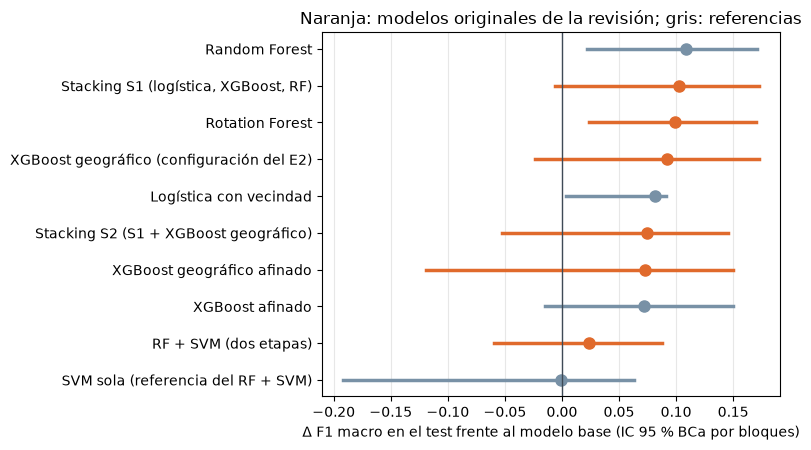

In [3]:
nombres = [n for n in sorted(te, key=lambda n: te[n]["vs_base"]["dif"] if te[n]["vs_base"] else -1) if n != base]
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, n in enumerate(nombres):
    t = te[n]["vs_base"]
    color = "#E06A2C" if n in ORIGINALES else "#7891A6"
    ax.plot(t["ic95_bca"], [i, i], color=color, lw=2.5)
    ax.plot(t["dif"], i, "o", color=color, ms=8)
ax.axvline(0, color="#3E4A56", lw=1)
ax.set_yticks(range(len(nombres)))
ax.set_yticklabels(nombres)
ax.set_xlabel("Δ F1 macro en el test frente al modelo base (IC 95 % BCa por bloques)")
ax.set_title("Naranja: modelos originales de la revisión; gris: referencias")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura.**

- **Rotation Forest:** es el modelo original con mejor desempeño. Empata con el mejor en la validación (0.598) y en el
  test supera al modelo base por **+0.099, IC [+0.024, +0.170]**, ganando en 6 de los 7 bloques: el único original
  cuyo intervalo excluye el 0.
- **Stacking:** la versión con logística, XGBoost y Random Forest tiene la misma validación (0.598) y +0.102 en el
  test, pero su intervalo toca el 0 ([−0.006, +0.173]). Agregarle el XGBoost geográfico lo empeora.
- **XGBoost geográfico:** la búsqueda con todos los datos eligió dar la mitad del peso a los modelos locales
  (α = 0.5, rejilla de 1 km, 5 % de vecinos por ancla) y subió la validación de 0.572 a 0.581, pero no mejoró el test
  (0.566 frente a 0.585 de la configuración del capítulo 8). Frente al XGBoost con el mismo modelo global, su parte
  geográfica no agrega F1 en el test (+0.001).
- **RF + SVM:** supera al base en la validación pero no en el test (+0.024, IC [−0.060, +0.088]).

**Sobre el intervalo del capítulo 8.** Con el método BCa, el +0.092 del XGBoost geográfico frente al base tiene IC
[−0.024, +0.172]; el capítulo 8 publicó [+0.034, +0.199] con bootstrap de percentiles. Con solo 7 bloques de test,
la confirmación de esa diferencia depende del método del intervalo; por eso la sección 9.4 usa una prueba con más
réplicas.

## 9.4 ¿Son estadísticamente significativas las diferencias?

Con 11 modelos se sigue una secuencia jerárquica: una prueba global (Friedman), comparaciones dirigidas con corrección
de Holm y el tamaño del efecto (delta de Cliff). La unidad con más réplicas son los **30 bloques espaciales de 2 km**
del entrenamiento con al menos 200 viviendas: el F1 de las predicciones fuera de muestra de cada modelo en cada
bloque. Con los 7 bloques de test, en cambio, el p-valor más pequeño posible es 0.016 y ninguna diferencia puede ser
significativa después de corregir por 10 comparaciones.

Friedman sobre 30 bloques: χ² = 39.0, gl = 10, p = 2.6e-05


,vs modelo base: p de Holm (Wilcoxon),vs modelo base: δ de Cliff,vs logística con vecindad: p de Holm (Wilcoxon),vs logística con vecindad: δ de Cliff
Logística con vecindad,0.007,+0.35 (mediano),—,—
XGBoost afinado,0.009,+0.48 (grande),1.0,+0.21 (pequeño)
XGBoost geográfico (configuración del E2),0.009,+0.43 (mediano),1.0,+0.18 (pequeño)
XGBoost geográfico afinado,0.004,+0.51 (grande),0.548,+0.24 (pequeño)
Random Forest,0.009,+0.43 (mediano),1.0,+0.14 (despreciable)
Rotation Forest,0.009,+0.45 (mediano),1.0,+0.15 (pequeño)
RF + SVM (dos etapas),0.1,+0.31 (pequeño),1.0,-0.04 (despreciable)
SVM sola (referencia del RF + SVM),0.1,+0.18 (pequeño),0.858,-0.16 (pequeño)
"Stacking S1 (logística, XGBoost, RF)",0.009,+0.44 (mediano),1.0,+0.07 (despreciable)
Stacking S2 (S1 + XGBoost geográfico),0.009,+0.43 (mediano),1.0,+0.11 (despreciable)


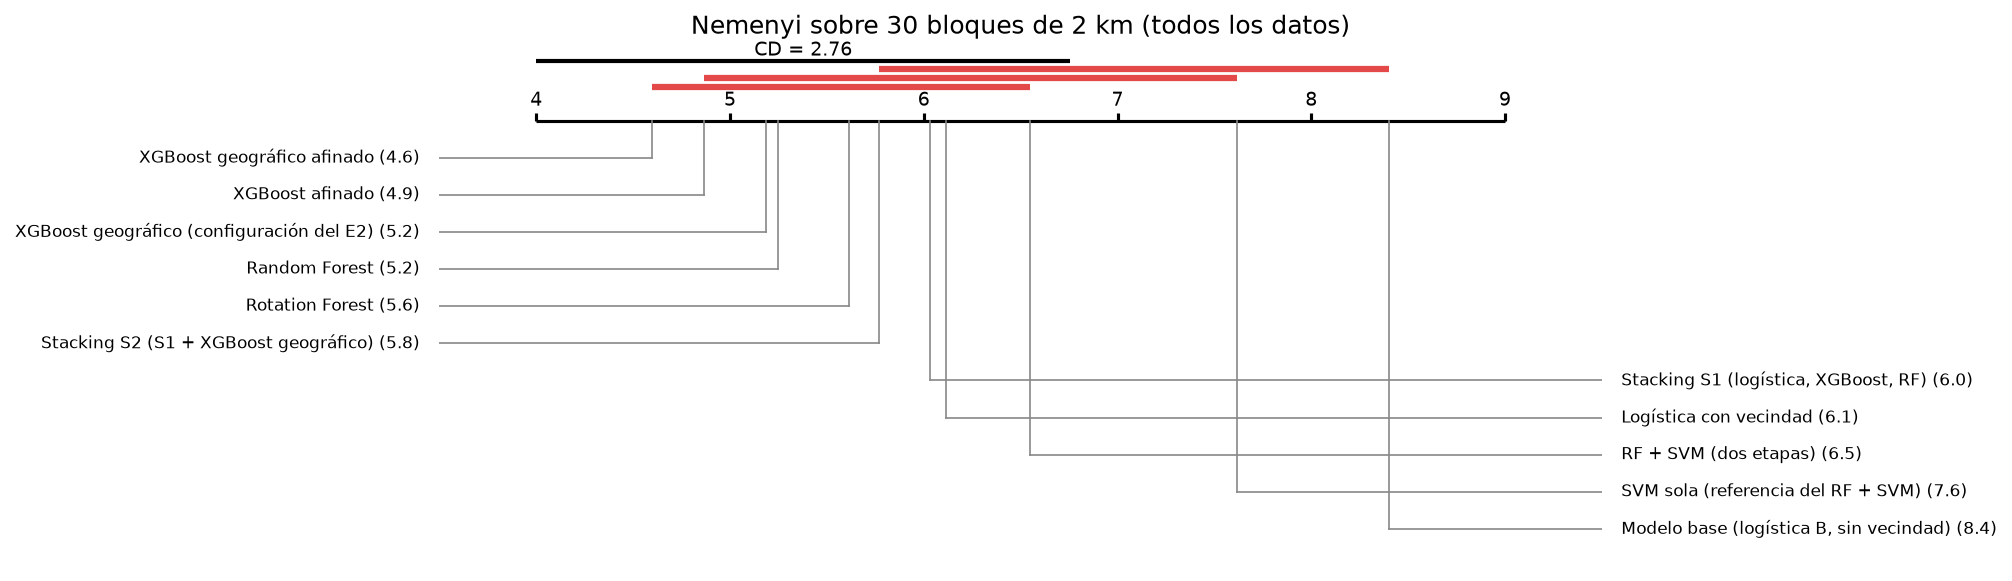

In [4]:
fr = ES["friedman"]
print(f"Friedman sobre {ES['bloques']['n_usados']} bloques: χ² = {fr['chi2']:.1f}, gl = {fr['gl']}, p = {fr['p']:.1e}")
tablas = {}
for fam in ("vs modelo base", "vs logística con vecindad"):
    for r in ES["comparaciones"][fam]:
        tablas.setdefault(r["a"], {})[f"{fam}: p de Holm (Wilcoxon)"] = round(r["wilcoxon_p_holm"], 4)
        tablas[r["a"]][f"{fam}: δ de Cliff"] = f"{r['delta_cliff']:+.2f} ({r['magnitud']})"
display(pd.DataFrame(tablas).T.fillna("—"))
display(Image(filename=str(RV / "cd_mejoras.png")))

**Lectura.**

- **Frente al modelo base, la mejora es significativa para todos los modelos con vecindad física**, originales o no
  (Wilcoxon con Holm, p < 0.01), con efecto **mediano a grande**: δ de Cliff 0.45 el Rotation Forest, 0.43 y 0.44 los
  stacking, 0.43 y 0.51 el XGBoost geográfico (configuración del capítulo 8 y afinado). El RF + SVM no lo es
  (p = 0.10).
- **Frente a la logística con las mismas variables, ninguna diferencia es significativa** (p de Holm ≥ 0.54, efectos
  despreciables o pequeños). Tampoco entre el XGBoost geográfico y el XGBoost (δ = 0.02).

## 9.5 Respuesta

```{admonition} ¿Algún modelo original de la revisión supera al modelo base?
:class: important
**Sí, con la información del entorno de la vivienda.** Tres modelos que no se habían aplicado al estrato con datos
catastrales (el **XGBoost geográfico**, el **Rotation Forest** y el **stacking**) superan al modelo base en zonas
nuevas con significancia estadística y un efecto mediano a grande. El **Rotation Forest** es el más sólido: es el único
original cuyo intervalo de test frente al base excluye el 0 (+0.099, IC [+0.024, +0.170], 6 de 7 bloques).

**Pero la mejora no es del algoritmo.** Frente a modelos convencionales que reciben la misma vecindad física (la
logística, XGBoost o Random Forest), ningún modelo original gana de forma significativa. Lo que hace superar al
modelo base es describir el entorno de la vivienda; los modelos originales lo aprovechan igual de bien, no mejor. La
ventaja propia del XGBoost geográfico sigue estando en las zonas con datos cerca (capítulo 8).
```